2°: 15.24 µm
Grid shape: (1000, 1000)
Field shape: (1000, 1000)
Intensity shape: (1000, 1000)
Maximum intensity: 15.999988364743933
Minimum intensity: 1.1635256070310472e-05
Fringe visibility: 0.9999985455929912


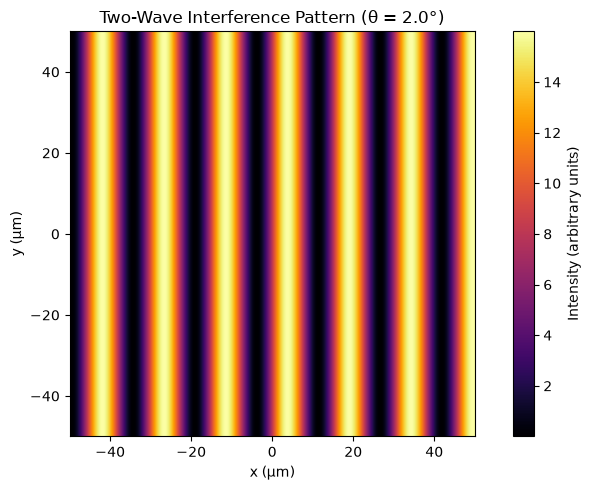

4°: 7.62 µm
Grid shape: (1000, 1000)
Field shape: (1000, 1000)
Intensity shape: (1000, 1000)
Maximum intensity: 15.99996678664891
Minimum intensity: 3.3213351090219474e-05
Fringe visibility: 0.9999958483311138


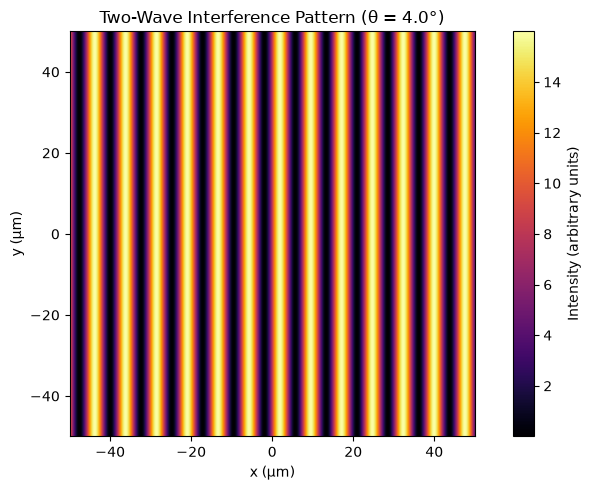

7°: 4.36 µm
Grid shape: (1000, 1000)
Field shape: (1000, 1000)
Intensity shape: (1000, 1000)
Maximum intensity: 15.99995338896277
Minimum intensity: 4.6611037229513476e-05
Fringe visibility: 0.9999941736203464


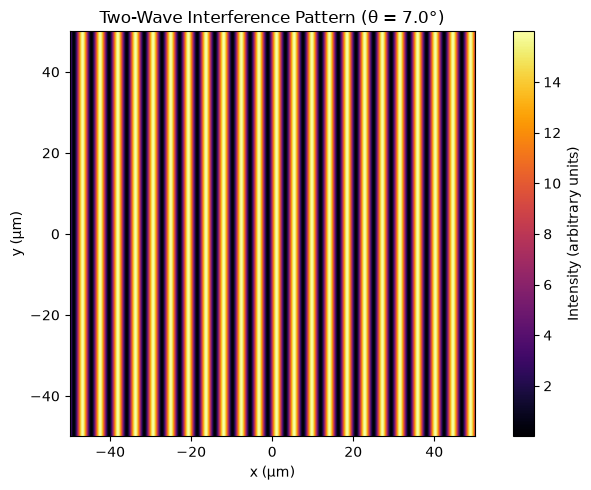

9°: 3.39 µm
Grid shape: (1000, 1000)
Field shape: (1000, 1000)
Intensity shape: (1000, 1000)
Maximum intensity: 15.999971564730131
Minimum intensity: 2.8435269870138702e-05
Fringe visibility: 0.9999964455912663


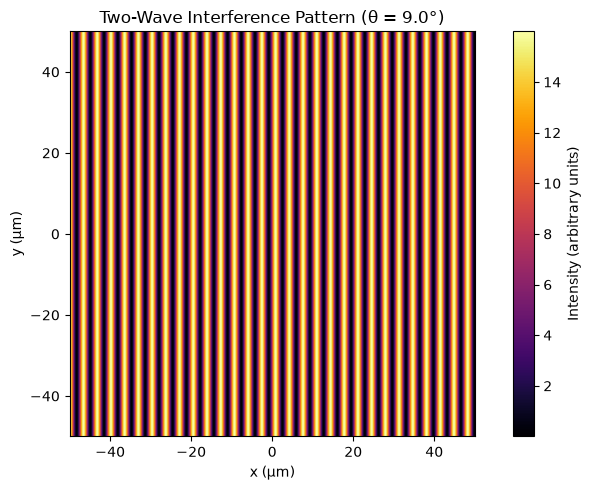

In [2]:
import numpy as np
import matplotlib.pyplot as plt

wavelength = 532e-9  # 532 nm
A1 = 2.0
A2 = 2.0
k = 2 * np. pi/wavelength

# ---------------------------------
# 2. Spatial grid
# ---------------------------------
x = np.linspace(-50e-6, 50e-6, 1000)
y = np.linspace(-50e-6, 50e-6, 1000)
X, Y = np.meshgrid(x, y)

# ---------------------------------
# 1. Optical parameters
# ---------------------------------
for angle_deg in [2, 4, 7, 9]: # Crossing angle: 2 degrees
    theta = np.deg2rad(angle_deg)
    # ---------------------------------
    # 3. Complex optical fields
    # Two plane waves crossing symmetrically
    # ---------------------------------
    phi0 = np.pi / 2
    phi1 = k * np.sin(theta / 2) * X
    phi2 = -k * np.sin(theta / 2) * X
    fringe_spacing = wavelength / (2 * np.sin(theta / 2))
    E1 = A1 * np.exp(1j * phi1)
    E2 = A2 * np.exp(1j * (phi2 + phi0))
    # ---------------------------------
    # 4. Interference intensity
    # ---------------------------------
    E_total = E1 + E2
    I = np.abs(E_total)**2
    # 5. Numerical verification
    I_max = np.max(I)
    I_min = np.min(I)
    visibility = (I_max - I_min) / (I_max + I_min)

    # ---------------------------------
    # 6. Visualization
    # ---------------------------------
    print(f"{angle_deg}°: {fringe_spacing * 1e6:.2f} µm")
    print("Grid shape:", X.shape)
    print("Field shape:", E_total.shape)
    print("Intensity shape:", I.shape)
    print("Maximum intensity:", I_max)
    print("Minimum intensity:", I_min)
    print("Fringe visibility:", visibility)
    plt.figure(figsize=(8, 5))

    plt.imshow(
        I,
        extent=[x.min()*1e6, x.max()*1e6,
                y.min()*1e6, y.max()*1e6],
        origin="lower",
        cmap="inferno",
        aspect="equal"
    )

    plt.colorbar(label="Intensity (arbitrary units)")
    plt.xlabel("x (µm)")
    plt.ylabel("y (µm)")
    plt.title(f"Two-Wave Interference Pattern (θ = {np.rad2deg(theta):.1f}°)")

    plt.tight_layout()
    plt.show()